# Лабораторная работа 01  
## Анализ аудио: от волновой формы к признакам ASR

Цель работы - научиться **проверять аудио до запуска ASR** и связывать визуальные признаки сигнала с возможными ошибками распознавания.

В работе последовательно рассмотрим:

1. базовую статистику WAV-файлов;
2. waveform - как меняется амплитуда во времени;
3. STFT-спектрограмму - какие частоты присутствуют в каждый момент;
4. log-Mel-спектрограмму - более компактное представление спектра;
5. MFCC - ещё более сжатое описание спектральной формы;
6. влияние шума, реверберации, клиппинга и ускорения на признаки, которые затем получает ASR.


Для экспериментов используются синтетические `speech-like` сигналы из `make_lab_audio.py`, а параметры анализа берутся из `lab_01_audio_inspection.py`

## Шаг 0. Подготовка окружения

#### Импорт

Все графики сохраняются в `outputs/`, а затем выводятся прямо в notebook.

In [1]:
%matplotlib inline

import sys
from pathlib import Path


import librosa
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display


from scripts import make_lab_audio
from scripts import lab_01_audio_inspection as lab


LAB_DIR = Path.cwd()
WAV_DIR = LAB_DIR / "data" / "wav"
OUT_DIR = LAB_DIR / "outputs"

WAV_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("LAB_DIR:", LAB_DIR.resolve())
print("WAV_DIR:", WAV_DIR.resolve())
print("OUT_DIR:", OUT_DIR.resolve())

LAB_DIR: D:\МАГА\2 курс\ASR\lab_01_ru
WAV_DIR: D:\МАГА\2 курс\ASR\lab_01_ru\data\wav
OUT_DIR: D:\МАГА\2 курс\ASR\lab_01_ru\outputs


In [ ]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn-v0_8-whitegrid')  # Стильная сетка
plt.rcParams['figure.figsize'] = (10, 5)  # Размер по умолчанию
plt.rcParams['font.size'] = 10            # Размер шрифта
plt.rcParams['axes.labelsize'] = 12       # Размер подписей осей
plt.rcParams['axes.titlesize'] = 14       # Размер заголовков

# Для еще лучшего качества 
plt.rcParams['figure.dpi'] = 150          # Разрешение
plt.rcParams['savefig.dpi'] = 300         # Разрешение при сохранении
plt.rcParams['lines.linewidth'] = 1.5     # Толщина линий

#### Параметры признаков

In [2]:
feature_params = pd.DataFrame(
    {
        "Параметр": [
            "Частота дискретизации",
            "Длина FFT / окна",
            "Шаг окна",
            "Mel-полосы",
            "Коэффициенты MFCC",
            "Минимальная частота",
            "Максимальная частота",
        ],
        "Значение": [
            f"{lab.SAMPLE_RATE} Гц",
            f"{lab.N_FFT} отсчётов",
            f"{lab.HOP_LENGTH} отсчётов",
            lab.N_MELS,
            lab.N_MFCC,
            f"{lab.FMIN} Гц",
            f"{lab.FMAX} Гц",
        ],
    }
)

feature_params

,Параметр,Значение
0,Частота дискретизации,16000 Гц
1,Длина FFT / окна,400 отсчётов
2,Шаг окна,160 отсчётов
3,Mel-полосы,80
4,Коэффициенты MFCC,13
5,Минимальная частота,20 Гц
6,Максимальная частота,7600 Гц


При частоте дискретизации 16 кГц окно длиной 400 отсчётов соответствует **25 мс**, а шаг 160 отсчётов - **10 мс**.  
Именно поэтому речь анализируется как последовательность коротких почти стационарных фрагментов, а не как один длинный сигнал.

## Часть A. Генерация и первичная проверка аудиофайлов

Сгенерируем пять примеров:

- `clean_speech_like.wav` - исходный вариант без специально добавленных искажений;
- `noisy_speech_like.wav` - тот же сигнал + шум;
- `reverberant_speech_like.wav` - вариант с реверберацией, т.е. с "хвостами" отражений;
- `clipped_speech_like.wav` - сигнал с ограничением амплитуды;
- `speed_perturbed_speech_like.wav` - ускоренный вариант.

In [3]:
generated_paths = make_lab_audio.generate_lab_audio(WAV_DIR)
GENERATED_NAMES = [path.name for path in generated_paths]

for path in generated_paths:
    audio, sr = librosa.load(path, sr=None, mono=True)
    print(
        f"{path.name:36s} | "
        f"sr={sr:5d} Гц | "
        f"duration={len(audio) / sr:.3f} с | "
        f"peak={np.max(np.abs(audio)):.3f}"
    )

clean_speech_like.wav                | sr=16000 Гц | duration=5.200 с | peak=0.780
noisy_speech_like.wav                | sr=16000 Гц | duration=5.200 с | peak=0.920
reverberant_speech_like.wav          | sr=16000 Гц | duration=5.200 с | peak=0.880
clipped_speech_like.wav              | sr=16000 Гц | duration=5.200 с | peak=0.340
speed_perturbed_speech_like.wav      | sr=16000 Гц | duration=4.522 с | peak=0.780


### Ожидания до анализа

1. **Самая высокая RMS-энергия** ожидается у `noisy_speech_like.wav`: т.к. к исходному сигналу добавляется шум => доп-ая энергия и RMS будет выше, чем у др. искаженных 
2. **Самое заметное искажение волновой формы** ожидается у `clipped_speech_like.wav`: т.к. амплитуда принудительно ограничется, поэтому пики сигнала должны будут стать плоскими (пеньки)
3. **Наиболее размытые спектральные переходы** ожидаются у `reverberant_speech_like.wav`: т.к. отражения продолжат энергию после исходного события и растянут ее по времени

#### Прослушаем получившиеся примеры

In [4]:
for path in generated_paths:
    print(path.name)
    display(Audio(filename=str(path)))

clean_speech_like.wav


noisy_speech_like.wav


reverberant_speech_like.wav


clipped_speech_like.wav


speed_perturbed_speech_like.wav


## Часть B. Статистика аудио

Для каждого WAV-файла:

- длительность;
- число отсчётов;
- пиковую амплитуду;
- RMS;
- долю отсчётов, относимых к тишине;
- долю клиппированных отсчётов.

*Используем функции, из `lab_01_audio_inspection.py`

In [5]:
audio_data = {}
summary_rows = []

for name in GENERATED_NAMES:
    audio, sr = lab.load_audio(WAV_DIR / name)
    audio_data[name] = (audio, sr)
    summary_rows.append(lab.summarize_audio(name, audio, sr))

summary = pd.DataFrame(summary_rows)
summary

,filename,sample_rate_hz,duration_s,num_samples,peak_amplitude,rms,silence_fraction,clipping_fraction
0,clean_speech_like.wav,16000,5.200,83200,0.780029,0.250151,0.388930,0.000024
1,noisy_speech_like.wav,16000,5.200,83200,0.920013,0.265441,0.077200,0.000012
2,reverberant_speech_like.wav,16000,5.200,83200,0.880005,0.216411,0.385096,0.000108
3,clipped_speech_like.wav,16000,5.200,83200,0.340027,0.245213,0.298690,0.463798
4,speed_perturbed_speech_like.wav,16000,4.522,72348,0.780029,0.250186,0.389244,0.000014


| Файл | Длительность, с | Пик | RMS | Доля тишины | Доля клиппинга |
|---|---:|---:|---:|---:|---:|
| clean | 5.200 | 0.780 | 0.250 | 0.3889 | 0.000024 |
| noisy | 5.200 | 0.920 | 0.265 | 0.0772 | 0.000012 |
| reverberant | 5.200 | 0.880 | 0.216 | 0.3851 | 0.000108 |
| clipped | 5.200 | 0.340 | 0.245 | 0.2987 | 0.463798 |
| speed_perturbed | 4.522 | 0.780 | 0.250 | 0.3892 | 0.000014 |

### Выводы по статистике

1. **Необычно высокая доля клиппинга** наблюдается у `clipped_speech_like.wav`. При генерации сигнал сначала усиливается, а затем ограничивается по амплитуде, поэтому значительная часть отсчётов оказывается на одном и том же предельном уровне.
**46.4%** сигнала находится на уровне ограничения. Для остальных файлов величина практически нулевая
3. **Самый короткий файл** - `speed_perturbed_speech_like.wav`. При коэффициенте скорости больше 1 сигнал воспроизводится быстрее, поэтому число отсчётов и длительность уменьшаются (**4.52 с** вместо 5.20 с).
    Содержимое просто "упаковали"/"сжали" с 83200 до 72348 отчетов
4. **Доля тишины важна для ASR**, потому что длинные участки без речи влияют на сегментацию и VAD. Ошибочное принятие тишины или фонового шума за речь может приводить к вставкам, неверным границам сегментов и галлюцинациям модели. (легендарные примеры с GigaAM по "субтитры подготовил ...")

#### Построим все графики

In [6]:
loaded = []

for name, (audio, sr) in audio_data.items():
    stem = Path(name).stem
    loaded.append((name, audio, sr))

    lab.save_waveform(
        audio, sr, name,
        OUT_DIR / f"{stem}_waveform.png",
    )
    lab.save_waveform(
        audio, sr, name,
        OUT_DIR / f"{stem}_waveform_zoom.png",
        zoom=True,
    )
    lab.save_stft_spectrogram(
        audio, sr, name,
        OUT_DIR / f"{stem}_stft_spectrogram.png",
    )
    lab.save_log_mel(
        audio, sr, name,
        OUT_DIR / f"{stem}_log_mel.png",
    )
    lab.save_mfcc(
        audio, sr, name,
        OUT_DIR / f"{stem}_mfcc.png",
    )

lab.write_summary_csv(summary_rows, OUT_DIR / "audio_summary.csv")
lab.save_contact_sheet(
    loaded,
    OUT_DIR / "feature_comparison_contact_sheet.png",
)

print(f"Графики сохранены в: {OUT_DIR.resolve()}")

Графики сохранены в: D:\МАГА\2 курс\ASR\lab_01_ru\outputs


In [7]:
def show_saved_plots(suffix, names=GENERATED_NAMES, row_height=3.8):
    # Показывает сохранённые скриптом графики для всех примеров.
    fig, axes = plt.subplots(
        len(names),
        1,
        figsize=(11, row_height * len(names)),
    )
    axes = np.atleast_1d(axes)

    for ax, name in zip(axes, names):
        image_path = OUT_DIR / f"{Path(name).stem}_{suffix}.png"
        ax.imshow(mpimg.imread(image_path))
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## Часть C. Волновая форма

Волновая форма показывает изменение **амплитуды во времени**

На ней удобно искать паузы, изменения громкости, шумовой фон и особенно клиппинг

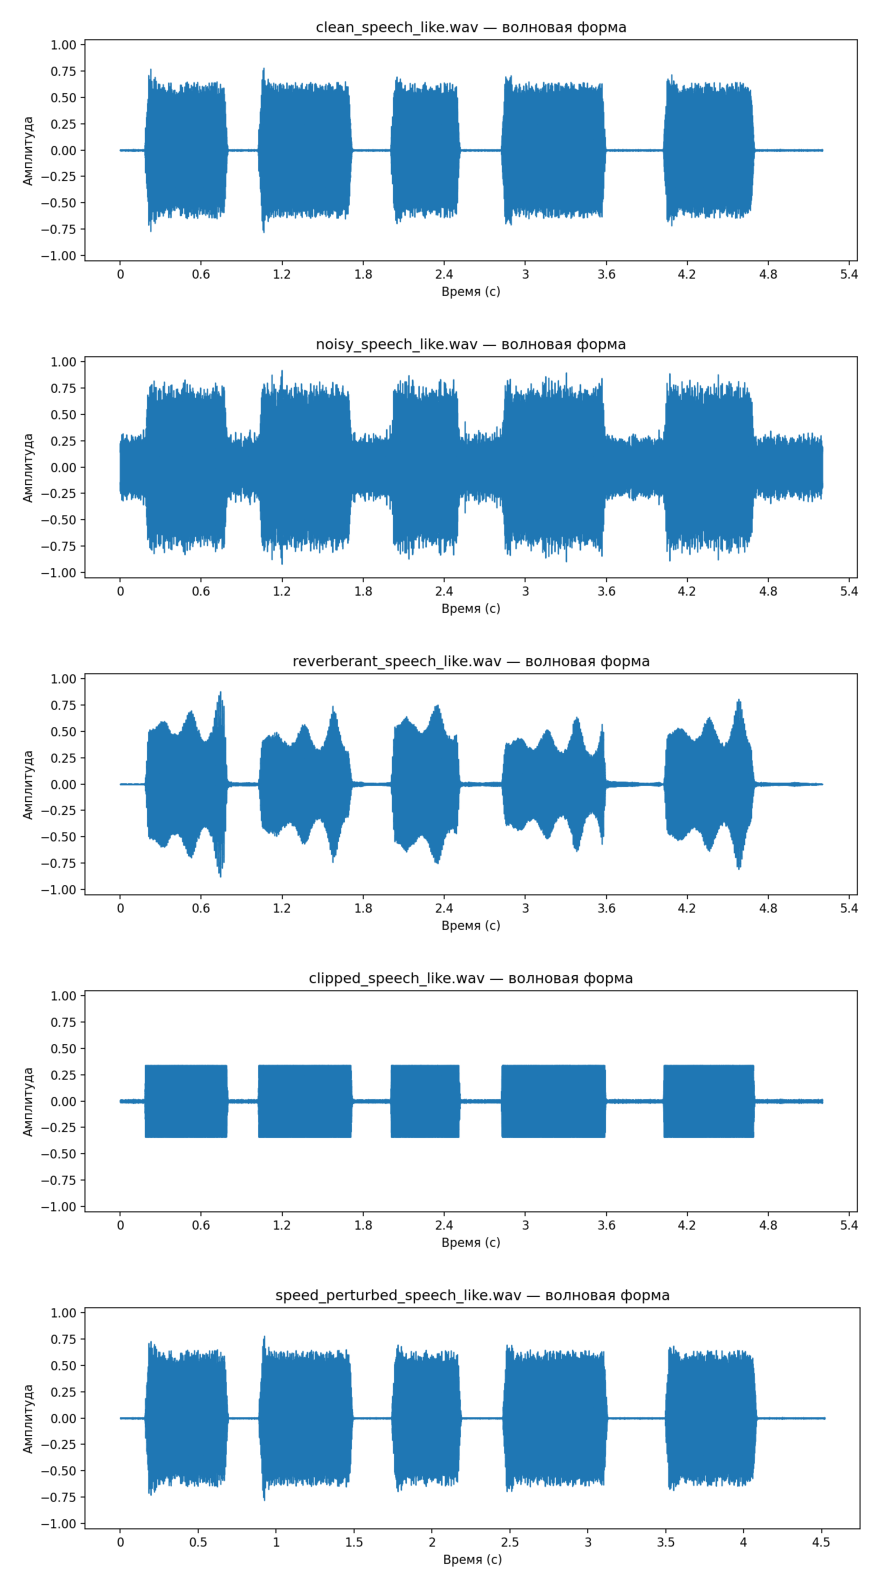

In [8]:
show_saved_plots("waveform", row_height=3.2)

#### Увеличенный фрагмент волновой формы (100 мс)

намного проще увидеть форму пиков и плоские участки после клиппинга

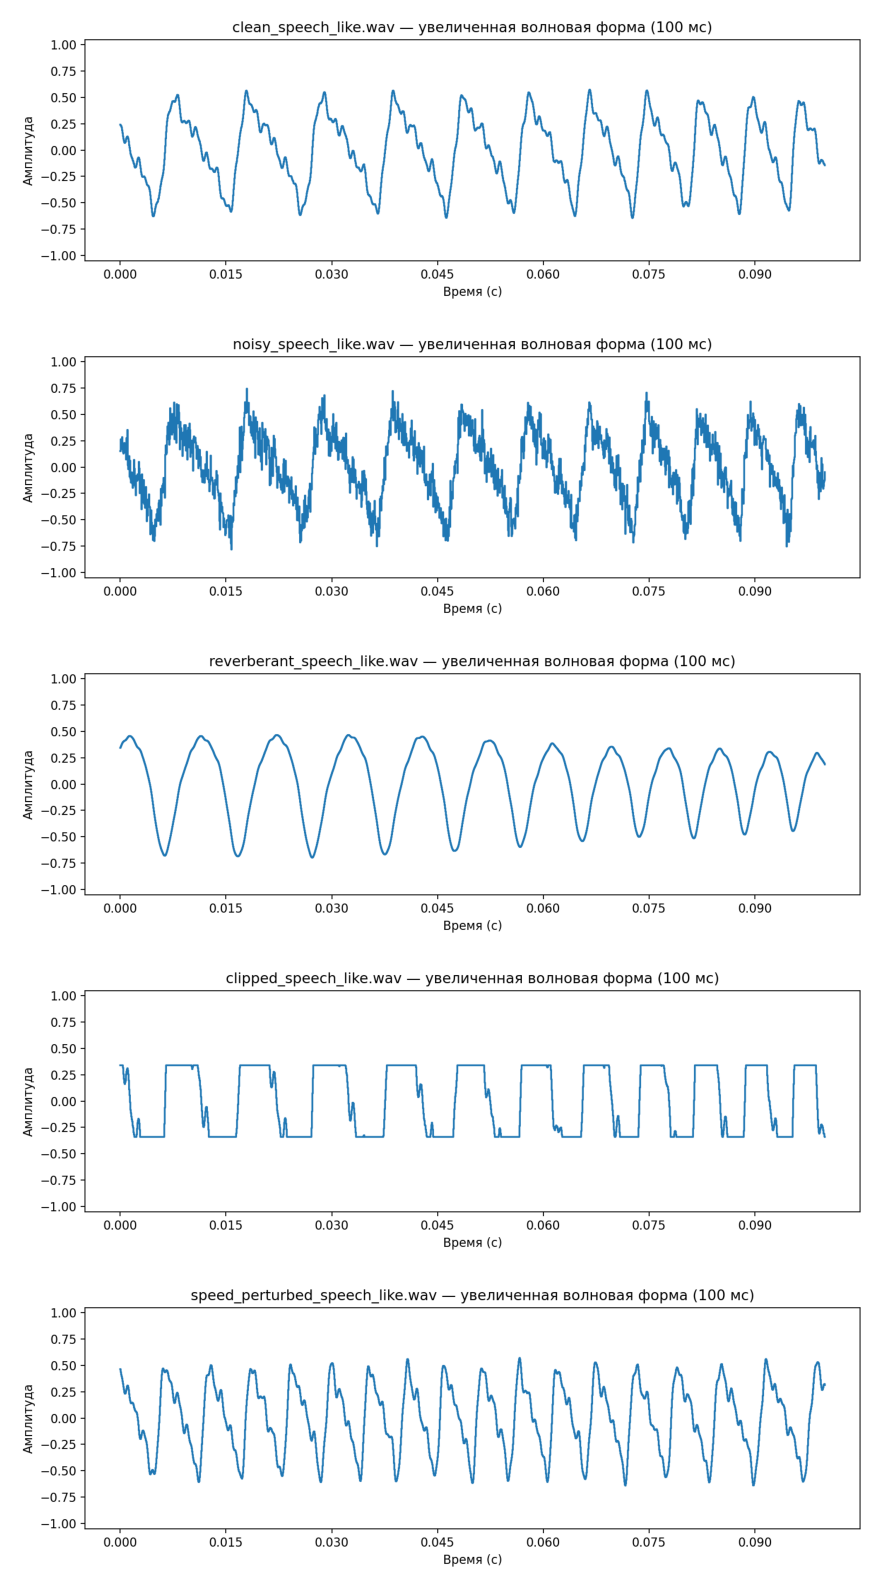

In [9]:
show_saved_plots("waveform_zoom", row_height=3.2)

### Выводы по волновой форме

1. **Легче всего увидеть клиппинг**: Шум и реверберация тоже меняют волну, но клиппинг выглядит особенно характерно: вместо нормальных пиков появляются длинные плоские участки
2. **Клиппинг выглядит как срезанные вершины** сигнала. Нормальная волна имеет естественные округлые пики, а при клиппинге их верхняя и нижняя части как будто срезаются ножницами. Получаются своеобразные плоские "пеньки" или плато
3. **Одной амплитуды недостаточно для понимания содержания речи**, потому что волна почти не показывает, какие именно частоты присутствуют в каждый момент времени. Два сигнала могут иметь схожую огибающую, но совершенно разный спектральный состав

## Часть D. Лог-спектрограмма STFT

STFT разбивает сигнал на короткие перекрывающиеся окна и показывает распределение энергии по **линейной шкале частот** во времени\
На графиках обращаем внимание на:

- низкочастотную voiced-структуру;
- широкополосный шум;
- вертикальные или размазанные переходы;
- спад энергии после speech-like событий в реверберированном аудио.

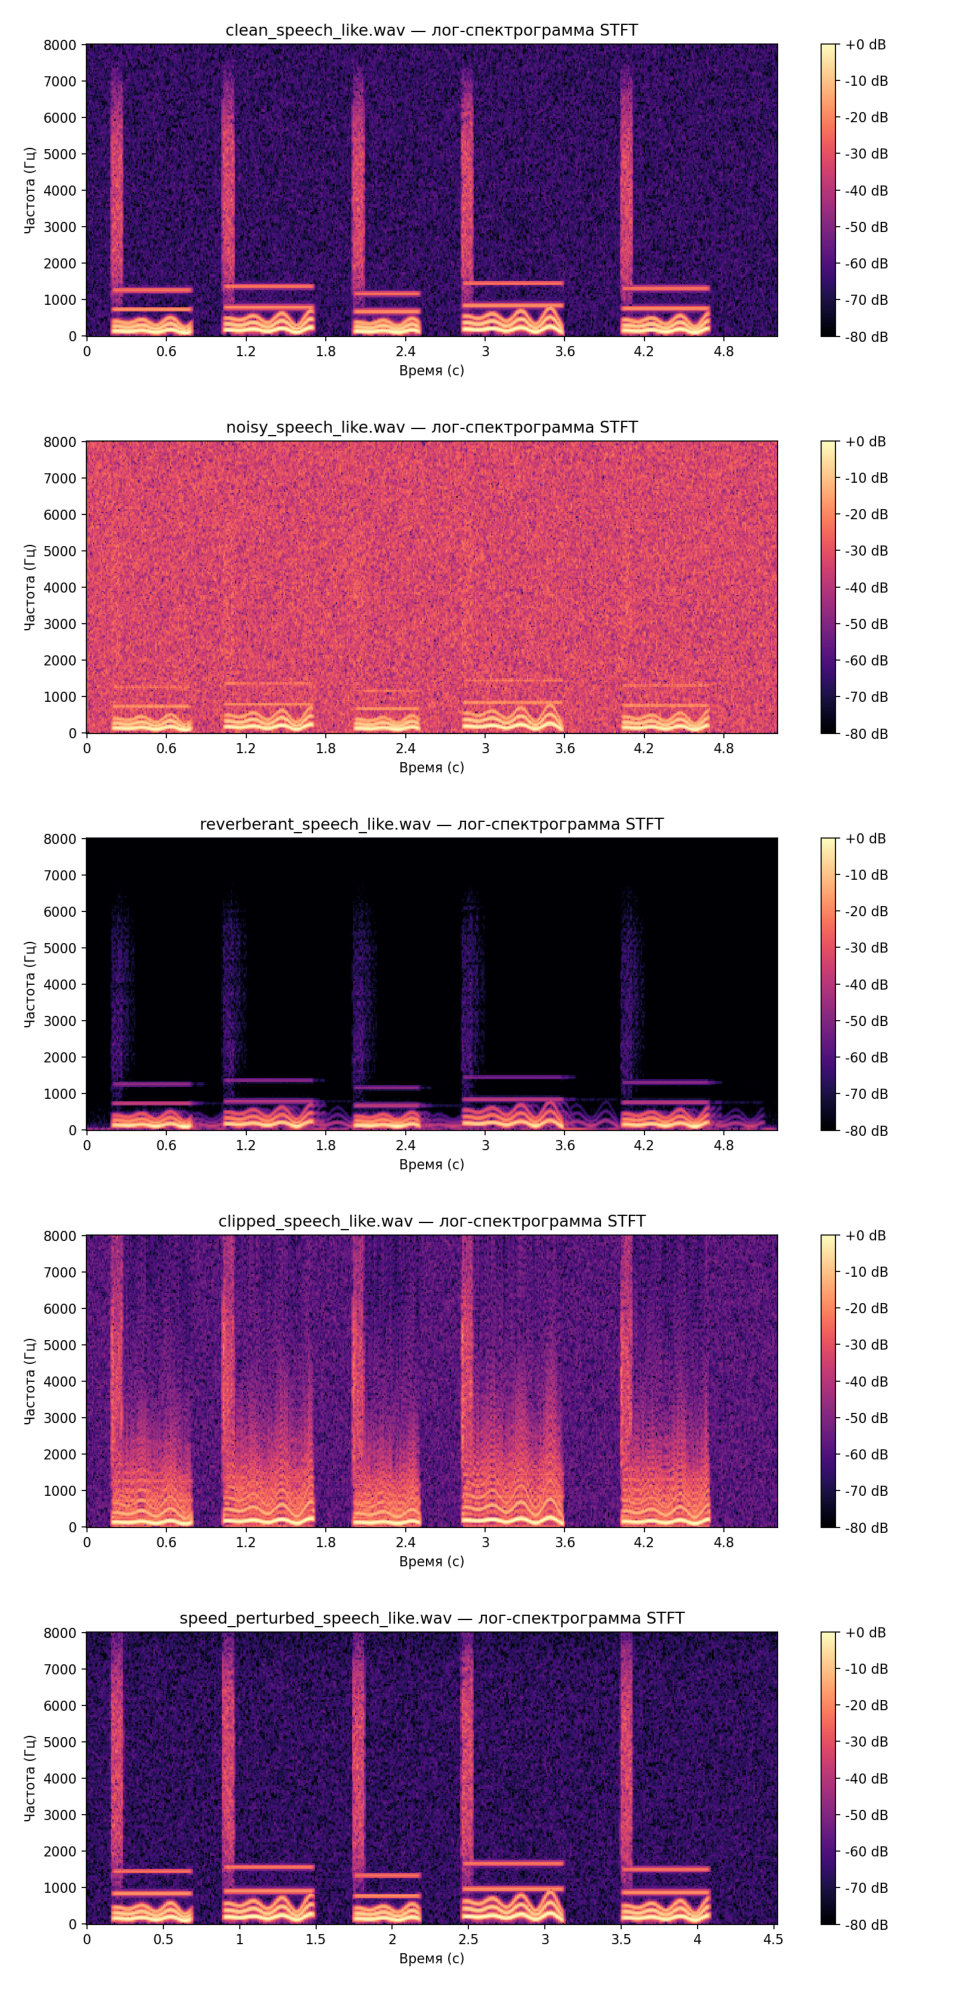

In [10]:
show_saved_plots("stft_spectrogram", row_height=4.0)

#### Дополнительно посчитаем долю энергии выше 4 кГц

In [11]:
def high_frequency_energy_share(audio, sr, low_hz=4000):
    stft = librosa.stft(
        audio,
        n_fft=lab.N_FFT,
        hop_length=lab.HOP_LENGTH,
        win_length=lab.WIN_LENGTH,
    )
    power = np.abs(stft) ** 2
    freqs = librosa.fft_frequencies(sr=sr, n_fft=lab.N_FFT)

    return float(power[freqs >= low_hz].sum() / power.sum())


hf_energy = pd.Series(
    {
        name: high_frequency_energy_share(audio, sr)
        for name, (audio, sr) in audio_data.items()
    },
    name="Доля энергии выше 4 кГц",
).sort_values(ascending=False)

hf_energy.to_frame()

,Доля энергии выше 4 кГц
noisy_speech_like.wav,0.070671
clipped_speech_like.wav,0.003618
speed_perturbed_speech_like.wav,0.002576
clean_speech_like.wav,0.001909
reverberant_speech_like.wav,0.000004


### Выводы по STFT

1. **Больше всего широкополосной высокочастотной энергии** у `noisy_speech_like.wav`. Белый шум распределяет энергию по широкому диапазону частот, в том числе там, где у чистого сигнала энергии мало (7.1% против 0.19%, разница более 30 раз)
2. **Реверберация размывает time-frequency паттерн по времени**: спектральные компоненты не обрываются сразу после окончания события, а продолжаются в виде затухающего хвоста
   В clean-сигнале событие заканчивается относительно резко, а в reverberant после него остаётся затухающий "хвост"
    Из-за этого соседние участки начинают сильнее накладываться друг на друга, а переходы выглядят размытыми
3. **Шум может вызывать замены и удаления в ASR**, потому что маскирует слабые речевые признаки. Модель может не обнаружить часть фонем либо сопоставить искажённый спектральный паттерн с другой фонемой

## Часть E. Log-Mel-спектрограмма

Log-Mel-представление сначала переводит спектр в **Mel-шкалу**, а затем логарифмирует энергии\
 используется 80 Mel-полос

Такое представление сохраняет time-frequency структуру речи, но делает её компактнее и ближе к тому, как различия частот воспринимаются слухом

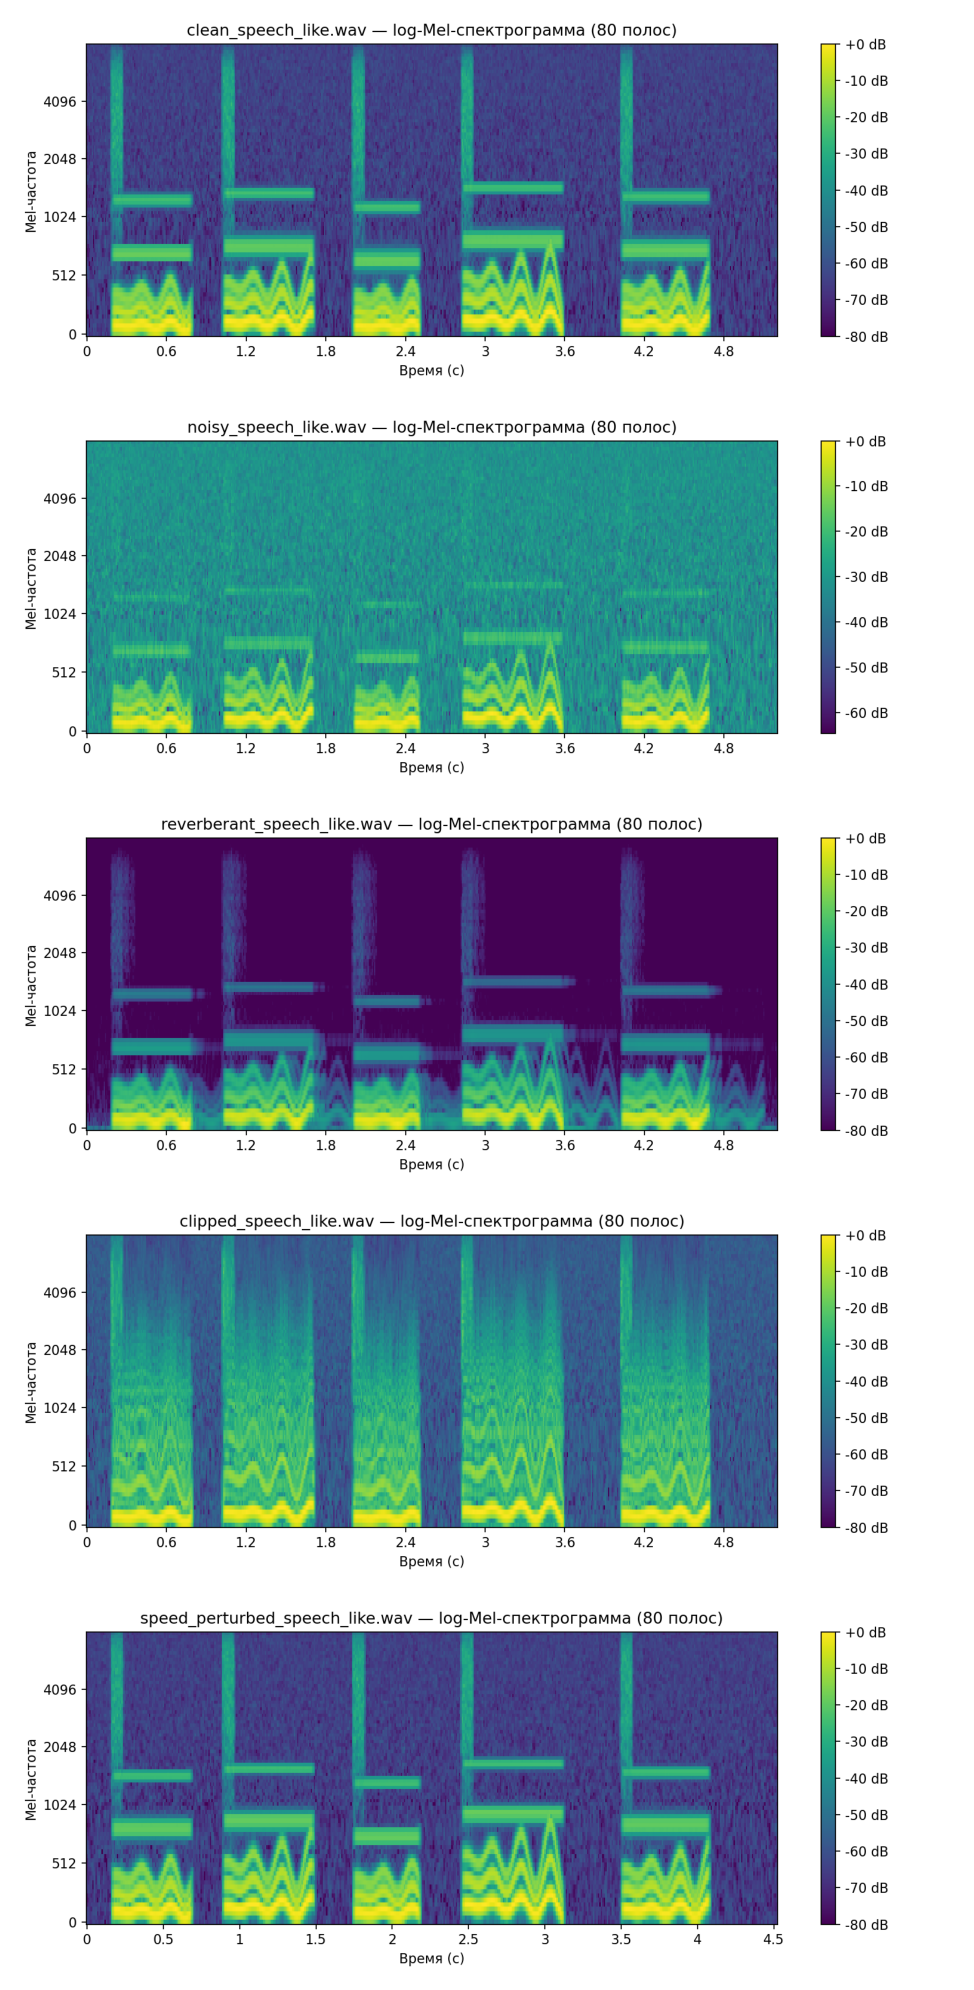

In [12]:
show_saved_plots("log_mel", row_height=4.0)

#### Сравним размерность STFT и log-Mel для clean

Посмотрим, сколько чисел приходится хранить на один временной кадр в каждом представлении

In [13]:
clean_audio, clean_sr = audio_data["clean_speech_like.wav"]

clean_stft = librosa.stft(
    clean_audio,
    n_fft=lab.N_FFT,
    hop_length=lab.HOP_LENGTH,
    win_length=lab.WIN_LENGTH,
)

clean_log_mel = lab.compute_log_mel(clean_audio, clean_sr)

pd.DataFrame(
    {
        "Представление": ["STFT", "Log-Mel"],
        "Частотных признаков": [clean_stft.shape[0], clean_log_mel.shape[0]],
        "Временных кадров": [clean_stft.shape[1], clean_log_mel.shape[1]],
    }
).set_index("Представление")

,Частотных признаков,Временных кадров
Представление,,
STFT,201,521
Log-Mel,80,521


* По времени ничего не потеряли <br>
    И STFT, и log-Mel дали по 521 временному кадру. То есть моменты начала/окончания событий остаются на той же временной сетке

* А вот частотное описание стало заметно компактнее:<br>
    STFT - 201 частотный bin на кадр, log-Mel - только 80 полос. Получается примерно в 2.5 раза меньше признаков по частотной оси


### Выводы по log-Mel

1. На **log-Mel легче увидеть в каких частотных областях находится энергия и как она меняется во времени**, поэтому здесь хорошо видны активные участки речи, паузы, шумовой фон и растягивание событий при реверберации.
Волна показывает в основном "насколько сильно колеблется сигнал", а log-Mel уже позволяет увидеть его спектральную структуру
2. По сравнению с линейно-частотной STFT **частотная информация сжимается**: множество FFT-бинов объединяется в меньшее число Mel-полос. Особенно уменьшается детализация на высоких частотах
3. **Логарифмические энергии полезны для речи**, потому что динамический диапазон спектра очень велик. Логарифм сжимает сильные компоненты и делает слабые, но информативные компоненты заметнее \
   Это похоже на фотографию, где есть одновременно очень светлые и очень тёмные области: после сжатия динамического диапазона детали становятся заметны и там, и там

## Часть F. MFCC

MFCC - ещё более компактное представление\
После Mel-фильтрации и логарифмирования применяется преобразование, которое описывает общую форму спектральной огибающей небольшим числом коэффициентов

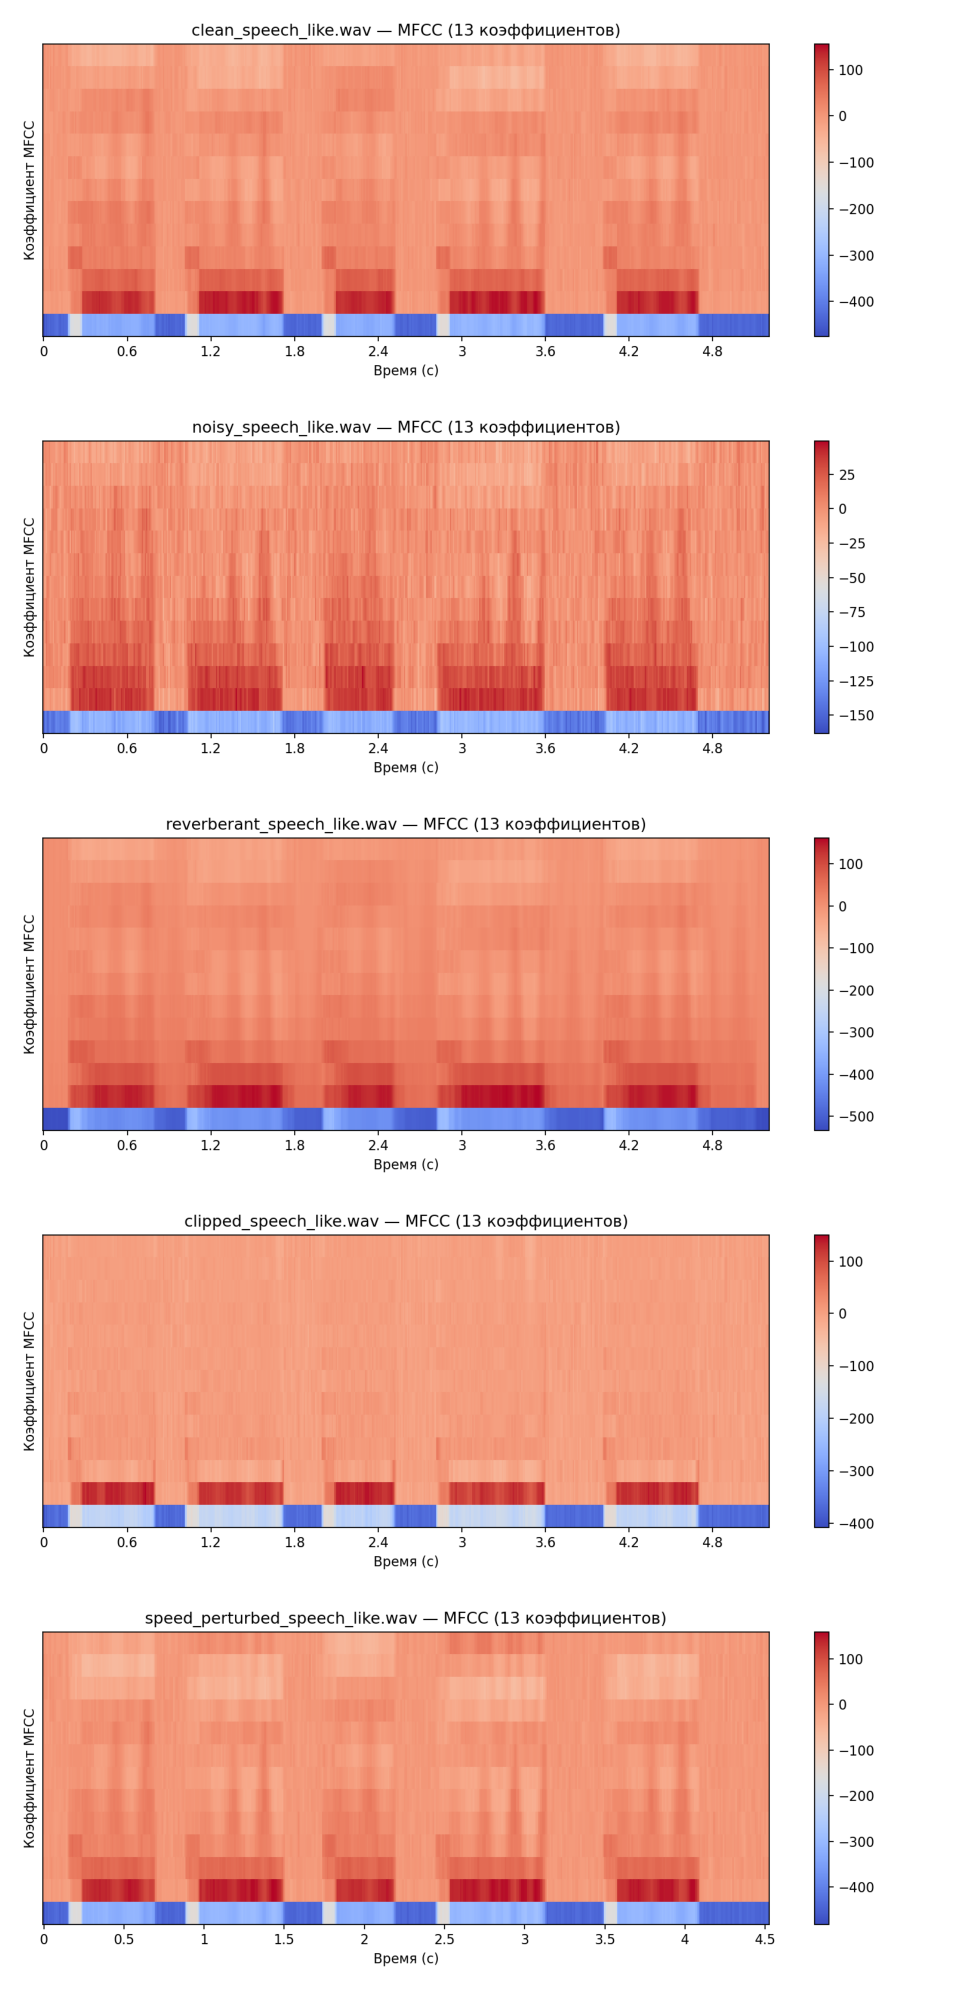

In [14]:
show_saved_plots("mfcc", row_height=4.0)

#### Сравним размерности STFT, log-Mel и MFCC

In [15]:
clean_mfcc = librosa.feature.mfcc(
    y=clean_audio,
    sr=clean_sr,
    n_mfcc=lab.N_MFCC,
    n_fft=lab.N_FFT,
    hop_length=lab.HOP_LENGTH,
    win_length=lab.WIN_LENGTH,
    n_mels=lab.N_MELS,
    fmin=lab.FMIN,
    fmax=lab.FMAX,
)

pd.DataFrame(
    {
        "Представление": ["STFT", "Log-Mel", "MFCC"],
        "Признаков на кадр": [
            clean_stft.shape[0],
            clean_log_mel.shape[0],
            clean_mfcc.shape[0],
        ],
        "Временных кадров": [
            clean_stft.shape[1],
            clean_log_mel.shape[1],
            clean_mfcc.shape[1],
        ],
    }
).set_index("Представление")

,Признаков на кадр,Временных кадров
Представление,,
STFT,201,521
Log-Mel,80,521
MFCC,13,521


### Выводы по MFCC

1. **MFCC визуально отличаются от log-Mel**: по вертикальной оси находятся уже не частотные полосы, а номера коэффициентов. Поэтому по MFCC нельзя напрямую читать конкретные частоты и гармоники
2. **Компактное представление полезно**, потому что уменьшает размерность данных и оставляет главным образом общую спектральную форму, важную для классических методов распознавания речи, а также в дальнейшем требует меньше вычислений
3. **Современный нейросетевой ASR часто предпочитает более богатые log-Mel признаки**, потому что нейросеть может сама научиться выделять нужные комбинации признаков. Слишком раннее сжатие в MFCC может удалить полезные детали

## Часть G. Сравнение чистого и искажённого аудио

Теперь сопоставим изменения сразу в нескольких представлениях и свяжем их с типичными ошибками ASR.

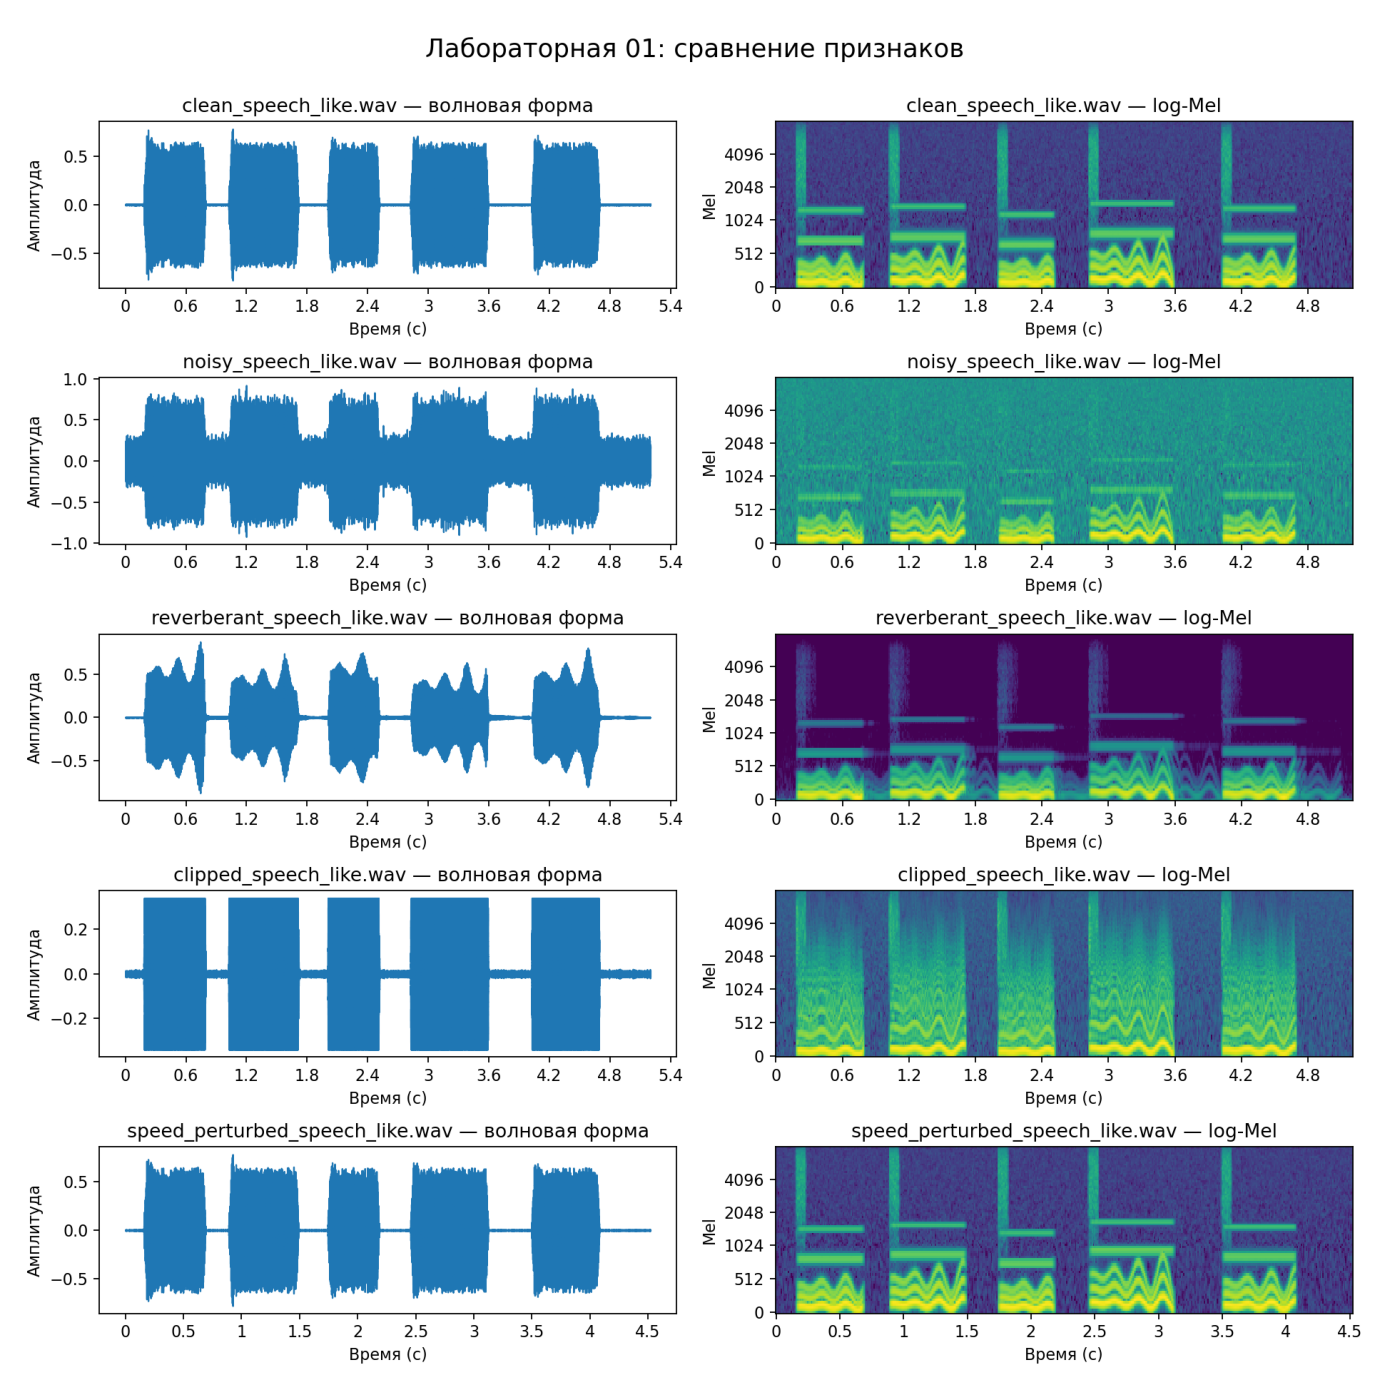

In [16]:
contact_sheet = OUT_DIR / "feature_comparison_contact_sheet.png"

plt.figure(figsize=(14, 14))
plt.imshow(mpimg.imread(contact_sheet))
plt.axis("off")
plt.tight_layout()
plt.show()

| Искажение | Что изменилось в волновой форме? | Что изменилось в спектрограмме / log-Mel? | Возможный тип ошибки ASR |
|---|---|---|---|
| **Шум** | Паузы заполняются фоновыми колебаниями; сигнал становится менее контрастным относительно тишины | Появляется широкополосная энергия, речевые компоненты частично маскируются | замены, удаления, вставки, плохое определение границ речи, галлюцинации на шуме |
| **Реверберация** | Огибающая становится более «растянутой», после речевых событий остаются хвосты | Энергия размазывается по времени, границы спектральных событий становятся менее резкими | замены, удаления, неверные временные метки, плохая сегментация |
| **Клиппинг** | Пики срезаются и превращаются в плоские плато | Возникают дополнительные гармоники и высокочастотные компоненты из-за нелинейного искажения | замены, удаления, ухудшение распознавания и downstream-обработки |
| **Ускорение** | Вся временная структура сжимается, события и паузы становятся короче | Спектральные события располагаются плотнее по времени | неверные временные метки, ошибки границ речи, возможные замены/удаления при сильном ускорении |

## Дополнительное задание. Собственная запись

Добавлю свой WAV-файл длительностью 5-10 секунд в `data/wav/` и сравню его со сгенерированными примерами

In [17]:
extra_wav = WAV_DIR / "1_6___.wav"

if not extra_wav:
    print("Дополнительная запись не найдена")

else:
    extra_audio, extra_sr = lab.load_audio(extra_wav)

    print(f"Пользовательская запись: {extra_wav.name}")
    print(
        f"Длительность: {len(extra_audio) / extra_sr:.2f} с | "
        f"sr={extra_sr} Гц | "
        f"peak={np.max(np.abs(extra_audio)):.3f}"
    )

    print()
    print("Своя запись:")
    display(Audio(extra_audio, rate=extra_sr))

Пользовательская запись: 1_6___.wav
Длительность: 6.00 с | sr=16000 Гц | peak=0.411

Своя запись:


In [18]:
comparison_stats = pd.DataFrame([
    lab.summarize_audio(
        "clean_speech_like.wav",
        clean_audio,
        clean_sr,
    ),
    lab.summarize_audio(
        extra_wav.name,
        extra_audio,
        extra_sr,
    ),
])

display(comparison_stats)

,filename,sample_rate_hz,duration_s,num_samples,peak_amplitude,rms,silence_fraction,clipping_fraction
0,clean_speech_like.wav,16000,5.2,83200,0.780029,0.250151,0.388930,0.000024
1,1_6___.wav,16000,6.0,96000,0.411198,0.040631,0.737625,0.000010


In [19]:
extra_stem = extra_wav.stem

lab.save_waveform(extra_audio, extra_sr, extra_wav.name, OUT_DIR / f"{extra_stem}_waveform.png")
lab.save_waveform(extra_audio, extra_sr, extra_wav.name, OUT_DIR / f"{extra_stem}_waveform_zoom.png", zoom=True)
lab.save_stft_spectrogram(extra_audio, extra_sr, extra_wav.name, OUT_DIR / f"{extra_stem}_stft_spectrogram.png")
lab.save_log_mel(extra_audio, extra_sr, extra_wav.name, OUT_DIR / f"{extra_stem}_log_mel.png")
lab.save_mfcc(extra_audio, extra_sr, extra_wav.name, OUT_DIR / f"{extra_stem}_mfcc.png")

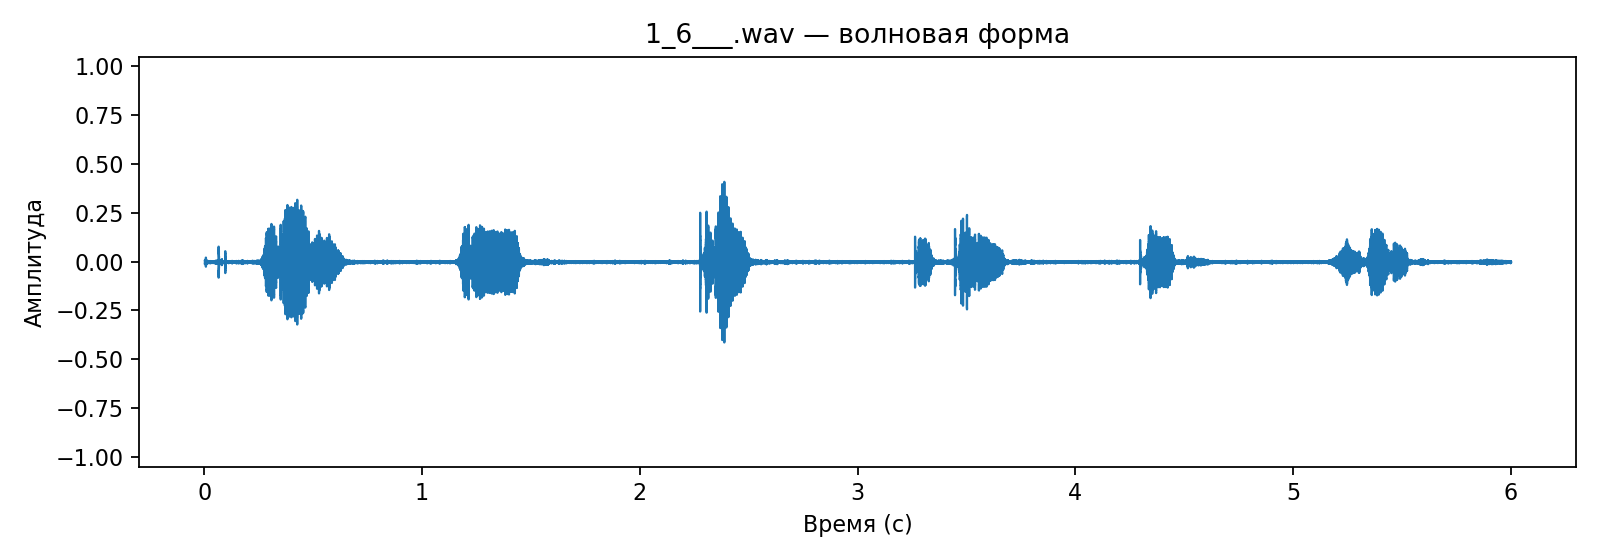

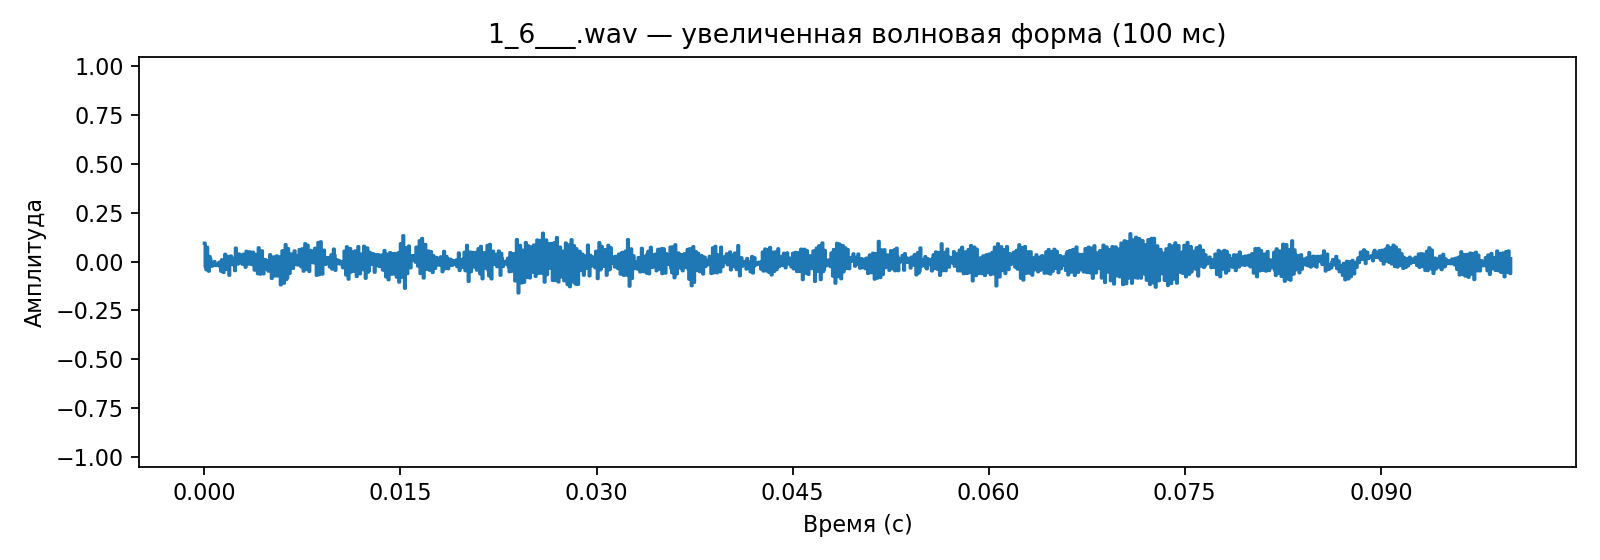

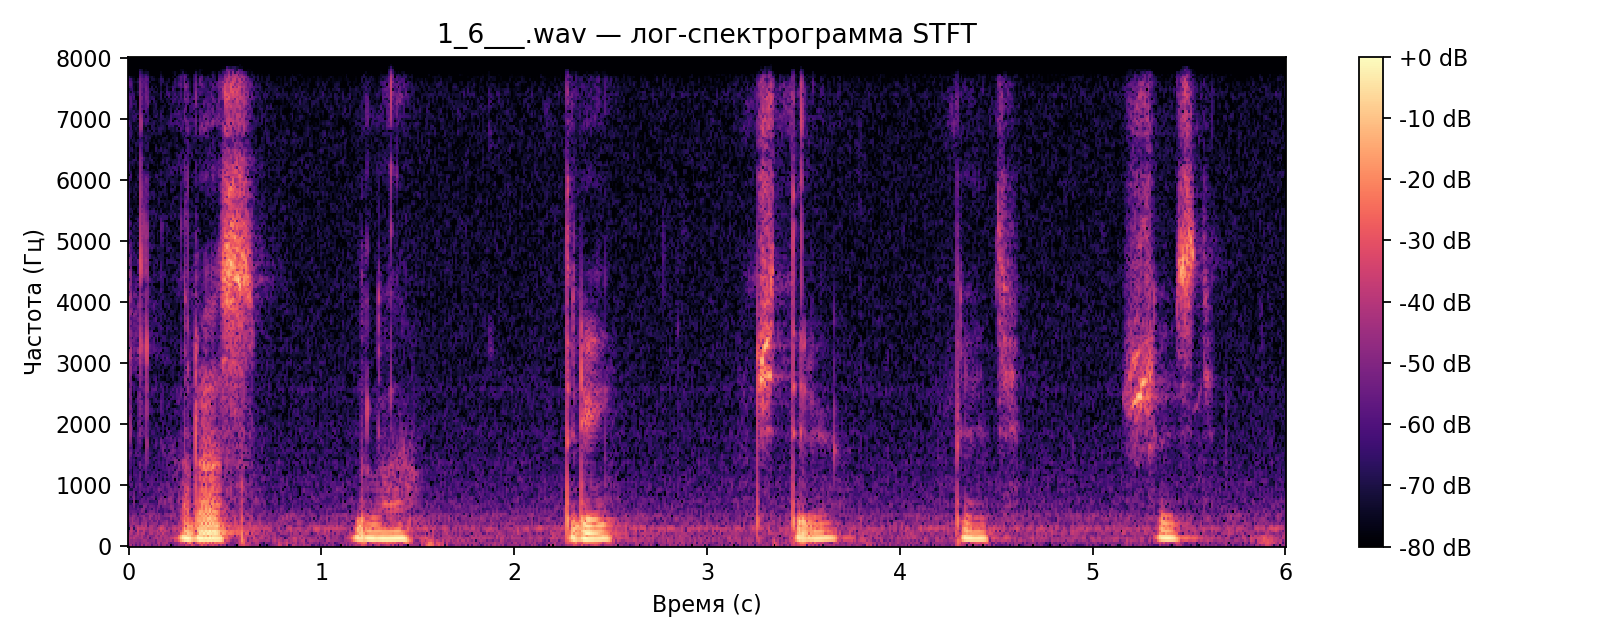

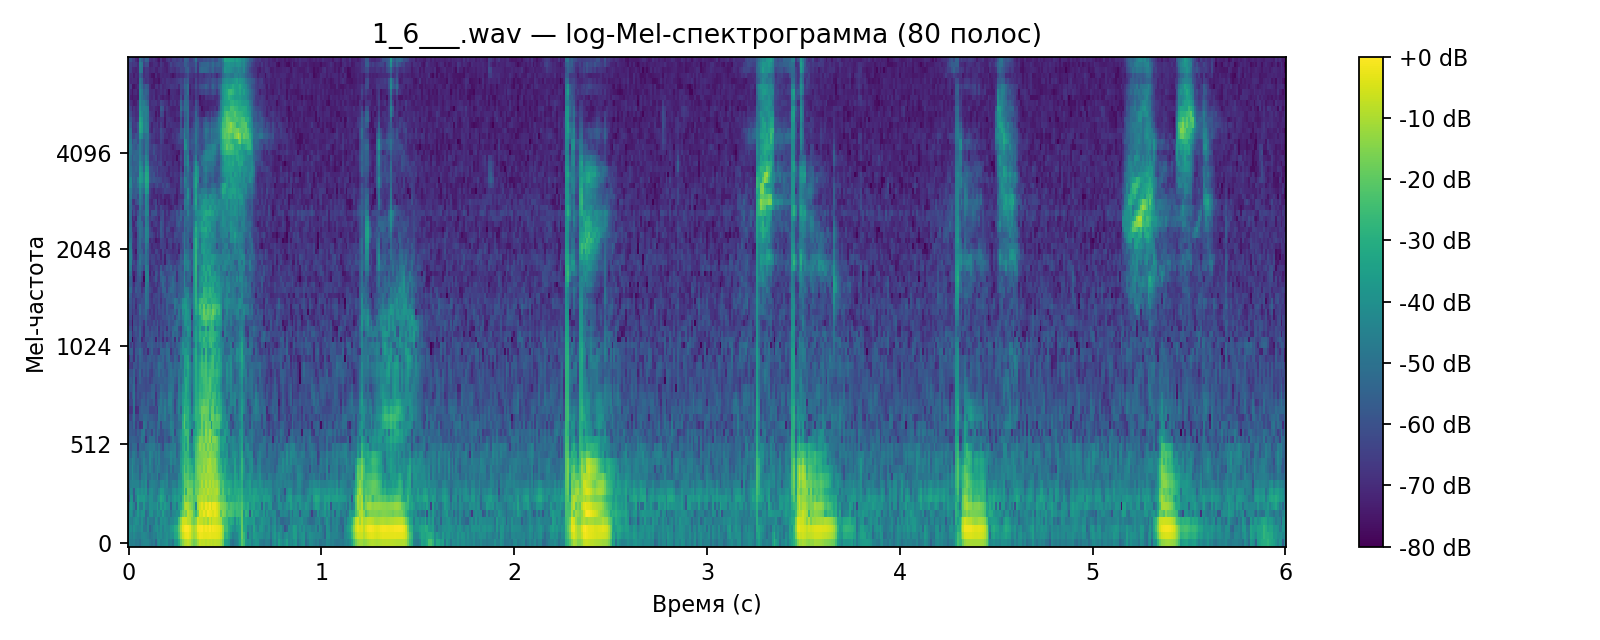

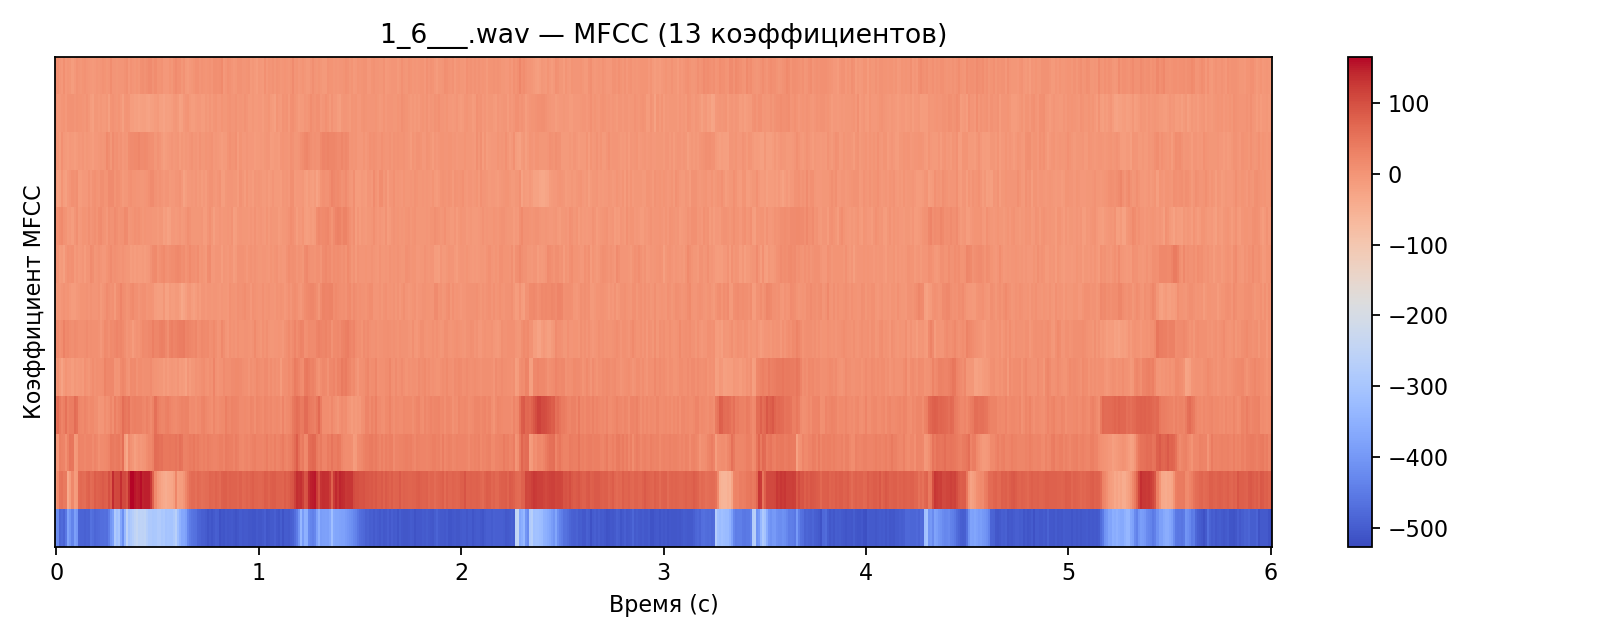

In [20]:
from IPython.display import display, Image

plots = [
    f"{extra_stem}_waveform.png",
    f"{extra_stem}_waveform_zoom.png",
    f"{extra_stem}_stft_spectrogram.png",
    f"{extra_stem}_log_mel.png",
    f"{extra_stem}_mfcc.png",
]

for plot in plots:
    display(Image(filename=str(OUT_DIR / plot)))

## Итог

В ходе лабораторной рассмотрены несколько уровней представления аудиосигнала:

- **waveform** хорошо показывает амплитуду, паузы и клиппинг
- **STFT** раскрывает частотный состав и позволяет увидеть шум и реверберацию
- **log-Mel** компактнее STFT и является типичным входным представлением для нейросетевого ASR
- **MFCC** ещё сильнее сжимает спектральную информацию и особенно характерен для классических ASR-пайплайнов

Главный практический вывод: перед тем как объяснять ошибку результатом работы ASR-модели, необходимо проверить качество входного аудио. Шум, реверберация, клиппинг, длина тишины и изменение временного масштаба уже на уровне признаков могут объяснить замены, удаления, вставки и ошибки сегментации